In [1]:
import rdkit
print(rdkit.__version__)

from rdkit.Chem import Descriptors

2026.03.6


formula : C16H14O6
heavy   : 22
rotb    : 2
inchikey: AIONOLUJZLIMTK-AWEZNQCLSA-N


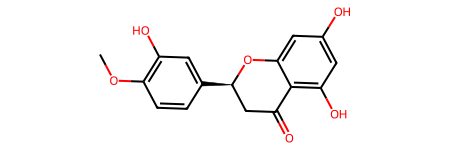

In [2]:
from rdkit import Chem
from rdkit.Chem import AllChem, rdMolDescriptors
 
smiles = " COC1=C(C=C(C=C1)[C@@H]2CC(=O)C3=C(C=C(C=C3O2)O)O)O"     #Hesperetin
mol = Chem.MolFromSmiles(smiles)
assert mol is not None, "SMILES did not parse: re-copy it from the menu"
 
print("formula :", rdMolDescriptors.CalcMolFormula(mol))
print("heavy   :", mol.GetNumHeavyAtoms())
print("rotb    :", rdMolDescriptors.CalcNumRotatableBonds(mol))
print("inchikey:", Chem.MolToInchiKey(mol))
mol             

In [3]:
molH = Chem.AddHs(mol)
print(molH.GetNumAtoms())

36


In [4]:
params = AllChem.ETKDGv3()
params.randomSeed = 232829
params.pruneRmsThresh = -1           # keep every embedding; duplicates are removed after optimization (section 5)
cids = list(AllChem.EmbedMultipleConfs(molH, numConfs=50, params=params))
print(len(cids), "conformers embedded")

50 conformers embedded


In [5]:
assert AllChem.MMFFHasAllMoleculeParams(molH), "MMFF94 has no parameters for this molecule: see troubleshooting"
res = AllChem.MMFFOptimizeMoleculeConfs(molH, maxIters=2000)
# res is a list of (flag, energy) pairs, one per conformer, in cids order:
#   flag 0 converged, 1 not converged, -1 could not be set up (energy reported as -1.0)
 
energies = {cid: e for cid, (flag, e) in zip(cids, res) if flag == 0}
print(len(energies), "converged of", len(res))

50 converged of 50


In [6]:
from rdkit.Chem import rdMolAlign
from rdkit.Geometry import Point3D
 
def mirror_copy(m):
    mm = Chem.Mol(m)
    for conf in mm.GetConformers():
        for i in range(mm.GetNumAtoms()):
            p = conf.GetAtomPosition(i)
            conf.SetAtomPosition(i, Point3D(-p.x, p.y, p.z))
    return mm
 
achiral = len(Chem.FindMolChiralCenters(molH, includeUnassigned=True, useLegacyImplementation=False)) == 0
mirror = mirror_copy(molH) if achiral else None
 
distinct = []                        # one conformer id per distinct minimum, lowest energy first
for cid in sorted(energies, key=energies.get):
    same = any(rdMolAlign.GetBestRMS(molH, molH, cid, k) <= 0.3
               or (achiral and rdMolAlign.GetBestRMS(mirror, molH, cid, k) <= 0.3)
               for k in distinct)
    if not same:
        distinct.append(cid)
 
e0 = energies[distinct[0]]
survivors = [cid for cid in distinct if (energies[cid] - e0) * 4.184 <= 12.6]
print(len(distinct), "distinct minima,", len(survivors), "survivors within 12.6 kJ/mol")
for cid in distinct:
    print(f"conf {cid:3d}   {energies[cid]:9.3f} kcal/mol   {(energies[cid] - e0) * 4.184:6.2f} kJ/mol")

11 distinct minima, 5 survivors within 12.6 kJ/mol
conf  31      34.597 kcal/mol     0.00 kJ/mol
conf  25      35.219 kcal/mol     2.60 kJ/mol
conf  30      35.967 kcal/mol     5.73 kJ/mol
conf  37      36.478 kcal/mol     7.87 kJ/mol
conf  27      36.729 kcal/mol     8.92 kJ/mol
conf  36      43.318 kcal/mol    36.49 kJ/mol
conf  20      44.494 kcal/mol    41.41 kJ/mol
conf  46      44.730 kcal/mol    42.39 kJ/mol
conf   8      45.034 kcal/mol    43.67 kJ/mol
conf   9      46.548 kcal/mol    50.00 kJ/mol
conf   4      46.779 kcal/mol    50.97 kJ/mol


In [7]:
def orca_coords(m, cid):
    conf = m.GetConformer(cid)
    lines = [f"* xyz {Chem.GetFormalCharge(m)} {Descriptors.NumRadicalElectrons(m) + 1}"]
    for atom in m.GetAtoms():
        pos = conf.GetAtomPosition(atom.GetIdx())
        lines.append(f"{atom.GetSymbol():<2s} {pos.x:12.6f} {pos.y:12.6f} {pos.z:12.6f}")
    lines.append("*")
    return "\n".join(lines) + "\n"
 
def orca_input(m, cid, title):
    mult = Descriptors.NumRadicalElectrons(m) + 1
    ks = "! UKS B3LYP" if mult > 1 else "! B3LYP"     # open shell needs UKS, stated explicitly
    head = (f"# {title}\n{ks} 6-31+G(d,p) CPCM(Water) Opt Freq RIJCOSX def2/J\n"
            f"%pal nprocs 4 end\n%maxcore 3000\n%scf MaxIter 300 end\n")
    return head + orca_coords(m, cid)
 
for rank, cid in enumerate(survivors, 1):
    Chem.MolToXYZFile(molH, f"conf{rank:02d}.xyz", confId=cid)          # for the visual check
    title = f"conf{rank:02d} seed 232829 MMFF94 {energies[cid]:.3f} kcal/mol"
    open(f"conf{rank:02d}.inp", "w").write(orca_input(molH, cid, title))
 
print(orca_input(molH, survivors[0], "conf01 seed 232829"))

# conf01 seed 232829
! B3LYP 6-31+G(d,p) CPCM(Water) Opt Freq RIJCOSX def2/J
%pal nprocs 4 end
%maxcore 3000
%scf MaxIter 300 end
* xyz 0 1
C     -6.029608     0.402510    -0.839746
O     -5.332429    -0.296430     0.185282
C     -3.964309    -0.213675     0.160662
C     -3.309946    -0.926624     1.170395
C     -1.923404    -0.941077     1.277548
C     -1.145510    -0.229543     0.354770
C     -1.798918     0.495338    -0.656621
C     -3.197011     0.501331    -0.755966
C      0.365974    -0.223653     0.488277
C      0.826062     0.999195     1.270217
C      2.322370     0.949341     1.379594
O      2.942631     1.432002     2.324401
C      3.055194     0.346271     0.251585
C      4.453846     0.347014     0.201071
C      5.117544    -0.184302    -0.902186
C      4.371898    -0.705847    -1.955940
C      2.979956    -0.713170    -1.917088
C      2.319626    -0.200225    -0.801901
O      0.950303    -0.241721    -0.825282
O      4.977093    -1.227494    -3.061010
O      5.235813     

In [8]:
# chiral centres: (atom index, "R"/"S", or "?" if unspecified)
print(Chem.FindMolChiralCenters(mol, includeUnassigned=True))
 
# double bonds with specified geometry
for b in mol.GetBonds():
    if b.GetStereo() != Chem.BondStereo.STEREONONE:
        print(b.GetBeginAtomIdx(), b.GetEndAtomIdx(), b.GetStereo())

[(8, 'S')]


In [9]:
def search(seed):
    m = Chem.AddHs(Chem.MolFromSmiles(smiles))
    p = AllChem.ETKDGv3(); p.randomSeed = seed; p.pruneRmsThresh = -1
    c = list(AllChem.EmbedMultipleConfs(m, numConfs=20, params=p))
    r = AllChem.MMFFOptimizeMoleculeConfs(m, maxIters=2000)
    return sorted(round(e, 4) for f, e in r if f == 0)
 
print(search(11) == search(11))   # True: same seed, same answer
print(search(11) == search(12))   # False: different seed, different search

True
False


In [10]:
import csv

lowest_energy = min(energies.values())  # Lowest converged MMFF94 energy, kcal/mol

with open("hesperetin_ensemble.csv", "w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow([
        "conformer_id", "mmff_flag", "mmff_energy_kcalmol",
        "relative_energy_kJmol"
    ])

    for cid, (flag, energy) in zip(cids, res):
        relative_energy = (energy - lowest_energy) * 4.184 if flag == 0 else ""
        writer.writerow([cid, flag, energy, relative_energy])

In [11]:
import csv

with open("hesperetin_survivors.csv", "w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow([
        "conformer_label", "conformer_id",
        "mmff_energy_kcalmol", "relative_energy_kJmol"
    ])

    for rank, cid in enumerate(survivors, start=1):
        energy = energies[cid]
        relative_energy = (energy - e0) * 4.184
        writer.writerow([f"conf{rank:02d}", cid, energy, relative_energy])